# 01 · Exploratory Data Analysis

Understand the retail dataset: volume, seasonality, product & customer behaviour. Everything downstream (forecasting, churn, segmentation) is driven by what we see here.

In [1]:
import sys, warnings, logging
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
logging.getLogger("cmdstanpy").setLevel(logging.ERROR)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": .3,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 140); pd.set_option("display.max_columns", 30)

from src.config import *
from src.ingestion.etl import load_processed
D = load_processed()
tx, customers, products, inventory = D["transactions"], D["customers"], D["products"], D["inventory"]
daily = D["daily"]
print(f"Loaded {len(tx):,} clean transaction lines | {tx.customer_id.nunique():,} customers | "
      f"{tx.order_date.min().date()} -> {tx.order_date.max().date()}")

Loaded 54,339 clean transaction lines | 1,455 customers | 2024-01-01 -> 2025-12-31


## 1. Shape & quality

In [2]:
import json
print(json.dumps(json.load(open(PROCESSED_DIR / "quality_report.json")), indent=2))
tx.head()

{
  "rows_raw": 54720,
  "rows_dropped_missing_keys": 0,
  "duplicates_removed": 163,
  "missing_prices_imputed": 109,
  "returns_or_invalid_removed": 218,
  "rows_clean": 54339,
  "date_min": "2024-01-01",
  "date_max": "2025-12-31",
  "customers": 1455,
  "products": 40
}


,order_id,order_date,customer_id,product_id,category,quantity,unit_price,store,revenue
0,O0000001,2024-01-01,C00009,P030,Beauty,1,41.09,Store A,41.09
1,O0000002,2024-01-01,C00014,P022,Electronics,1,165.76,Online,165.76
2,O0000003,2024-01-01,C00024,P023,Apparel,1,79.87,Store B,79.87
3,O0000004,2024-01-01,C00046,P022,Electronics,1,152.71,Online,152.71
4,O0000005,2024-01-01,C00046,P006,Grocery,4,14.01,Online,56.04


In [3]:
tx.describe(include="all").T[["count", "unique", "mean", "min", "max"]].fillna("")

,count,unique,mean,min,max
order_id,54339,54339,,,
order_date,54339,,2025-01-07 03:24:47.660796,2024-01-01 00:00:00,2025-12-31 00:00:00
customer_id,54339,1455,,,
product_id,54339,40,,,
category,54339,5,,,
quantity,54339.0,,1.774416,1.0,12.0
unit_price,54339.0,,93.504303,4.01,388.3
store,54339,4,,,
revenue,54339.0,,126.666179,4.02,1438.32


## 2. Revenue trend & growth

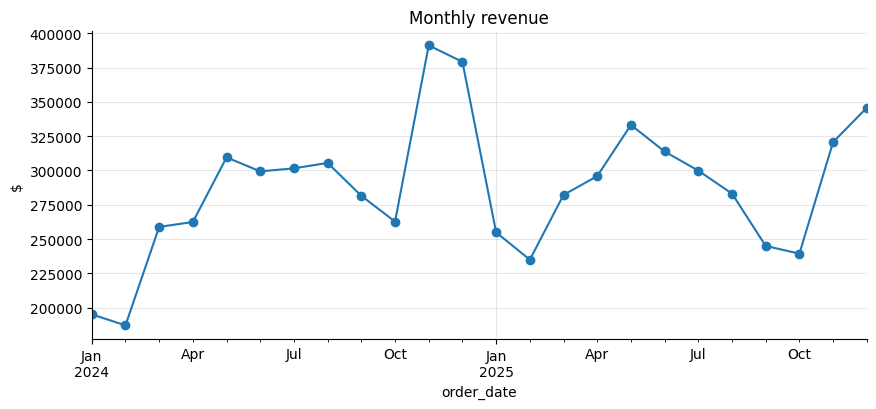

Latest-12m vs previous-12m growth: +0.4%


In [4]:
m = tx.set_index("order_date")["revenue"].resample("MS").sum()
ax = m.plot(marker="o", title="Monthly revenue"); ax.set_ylabel("$"); plt.show()
print(f"Latest-12m vs previous-12m growth: {m.iloc[-12:].sum() / m.iloc[:12].sum() - 1:+.1%}")

## 3. Seasonality: day-of-week and month
Weekends and Nov/Dec are clearly stronger - the forecasting models must capture both.

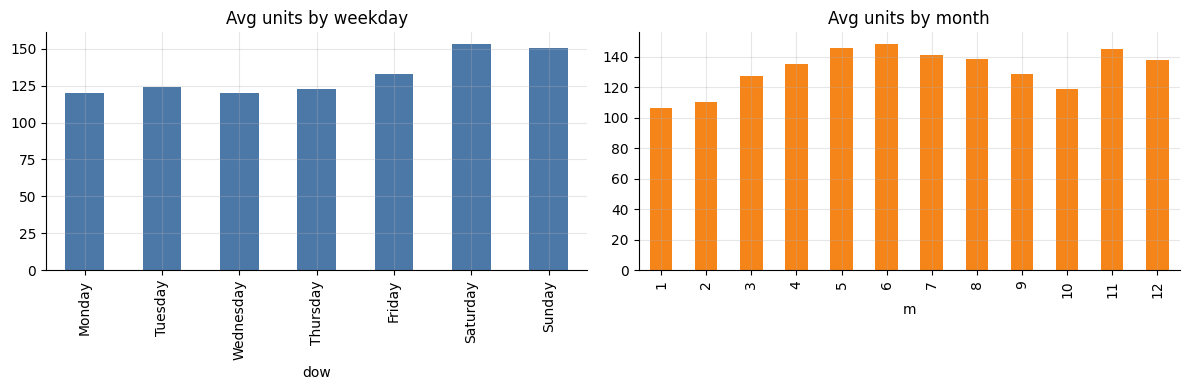

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
dow = daily.assign(dow=daily.date.dt.day_name()).groupby("dow")["units"].mean()
dow = dow.reindex(["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"])
dow.plot.bar(ax=ax[0], title="Avg units by weekday", color="#4c78a8")
daily.assign(m=daily.date.dt.month).groupby("m")["units"].mean().plot.bar(ax=ax[1], title="Avg units by month", color="#f58518")
plt.tight_layout(); plt.show()

## 4. Category & channel mix

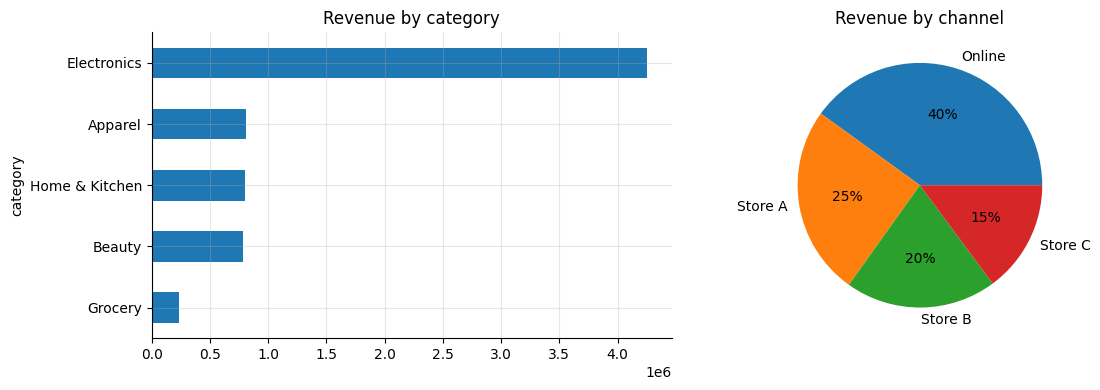

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
tx.groupby("category")["revenue"].sum().sort_values().plot.barh(ax=ax[0], title="Revenue by category")
tx.groupby("store")["revenue"].sum().plot.pie(ax=ax[1], autopct="%.0f%%", ylabel="", title="Revenue by channel")
plt.tight_layout(); plt.show()

## 5. Customers: order frequency is heavily skewed (a few customers drive most revenue)

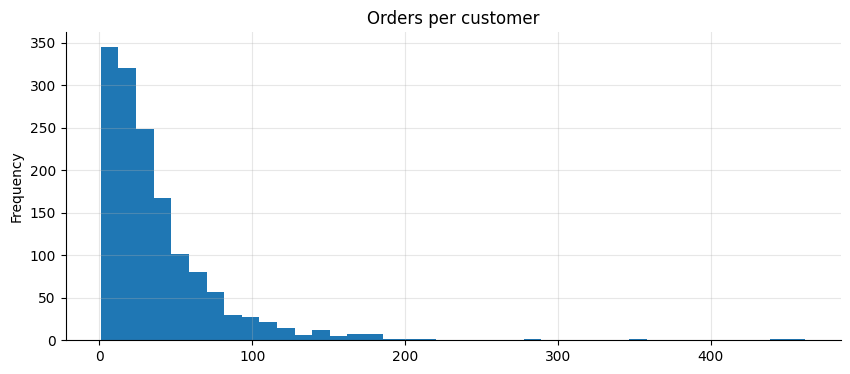

Top 20% of customers generate 52% of revenue


In [7]:
per_cust = tx.groupby("customer_id").agg(orders=("order_id", "nunique"), revenue=("revenue", "sum"))
per_cust["orders"].plot.hist(bins=40, title="Orders per customer"); plt.show()
s = per_cust["revenue"].sort_values(ascending=False)
print(f"Top 20% of customers generate {s.head(int(len(s)*.2)).sum() / s.sum():.0%} of revenue")

## 6. Product concentration (Pareto)

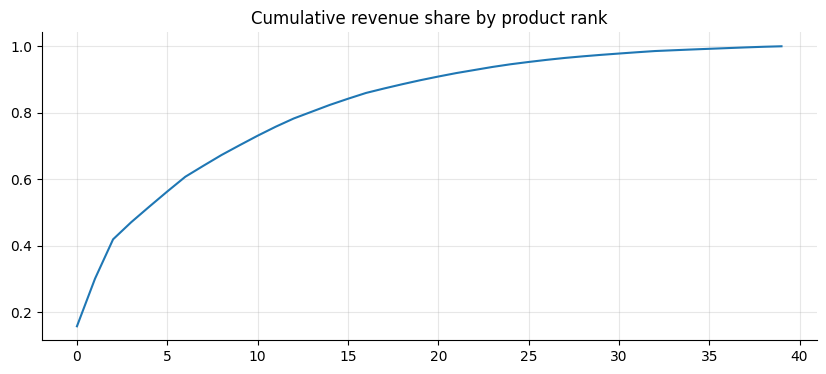

Top 10 of 40 products = 70% of revenue


In [8]:
p = tx.groupby("product_id")["revenue"].sum().sort_values(ascending=False)
(p.cumsum() / p.sum()).reset_index(drop=True).plot(title="Cumulative revenue share by product rank"); plt.show()
print(f"Top 10 of {len(p)} products = {p.head(10).sum() / p.sum():.0%} of revenue")